# Маркетплейс: удержание, повторные покупки и приоритеты роста

Итоговый анализ на основе структуры `final.ipynb`, с проверенными расчётами доставки
и полным ICE. Исходные ноутбуки сохранены отдельно.

**Бизнес-вопрос:** почему объём продаж перестал расти и какие изменения стоит проверить?
Доступны заказы, покупатели и товарные позиции. Комиссия, расходы, посещения сайта,
возвраты товаров и категории товаров отсутствуют. Поэтому здесь оцениваются объём
продаж и поведение покупателей, а не фактическая прибыль площадки.

Порядок работы: качество данных → retention → оценка PMF и доставки → пять метрик
→ ICE → метрики эксперимента → отчёт. Все числа в выводах формируются из расчётов.
Для воспроизведения выполнить **Restart Kernel → Run All** из папки проекта.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd()

# Последний условно полный месяц; см. проверку покрытия и чувствительности ниже.
OBS_END = pd.Period('2018-08', freq='M')
METRICS_START = pd.Period('2017-01', freq='M')
HYPOTHESIS_START = pd.Period('2017-06', freq='M')

def show_plot(name):
    plt.tight_layout()
    plt.show()
    plt.close()

def display_percent(frame, columns=None, decimals=3):
    formatted = frame.copy()
    for column in (frame.columns if columns is None else columns):
        formatted[column] = frame[column].map(
            lambda value: '—' if pd.isna(value) else f'{value:.{decimals}%}')
    display(formatted)

print(f'Python {sys.version.split()[0]}; pandas {pd.__version__}; NumPy {np.__version__}')


Python 3.13.7; pandas 3.1.0; NumPy 2.5.4


Matplotlib is building the font cache; this may take a moment.


## 0. Качество данных и границы анализа

`order_id` — заказ; `customer_id` — позаказный идентификатор покупателя;
`customer_unique_id` — идентификатор для объединения действий одного человека.
В `items` строка соответствует товарной позиции: ключ — `(order_id, order_item_id)`.
`price` — стоимость позиции, `freight_value` — стоимость доставки позиции, не вес;
`seller_id` — идентификатор продавца, не обязательно производителя.

`order_purchase_timestamp` используется как время оформления. Статус рассматривается
как последний известный: таблица не содержит историю переходов. Пропуск даты этапа
не доказывает отмену, а `canceled` не указывает инициатора отмены.


In [2]:
date_columns = ['order_purchase_timestamp', 'order_approved_at',
                'order_delivered_carrier_date', 'order_delivered_customer_date',
                'order_estimated_delivery_date']
orders = pd.read_csv(ROOT / 'olist_orders_dataset.csv', parse_dates=date_columns)
customers = pd.read_csv(ROOT / 'olist_customers_dataset.csv')
items = pd.read_csv(ROOT / 'olist_order_items_dataset.csv', parse_dates=['shipping_limit_date'])

assert orders['order_id'].notna().all() and orders['order_id'].is_unique
assert customers['customer_id'].notna().all() and customers['customer_id'].is_unique
assert customers['customer_unique_id'].notna().all()
assert orders['order_purchase_timestamp'].notna().all()
assert not items.duplicated(['order_id', 'order_item_id']).any()
assert items['order_id'].isin(orders['order_id']).all()
assert items[['price', 'freight_value']].notna().all().all()
assert items[['price', 'freight_value']].ge(0).all().all()

events_all = orders.merge(customers, on='customer_id', how='left',
                          validate='many_to_one', indicator=True)
assert events_all['_merge'].eq('both').all()
events_all = events_all.drop(columns='_merge')
events_all['order_month'] = events_all['order_purchase_timestamp'].dt.to_period('M')
assert len(events_all) == len(orders)

display(pd.DataFrame({'rows': [len(orders), len(customers), len(items)],
                      'table': ['orders', 'customers', 'items']}).set_index('table'))
display(orders.isna().sum().rename('missing').to_frame())
status_summary = orders.groupby('order_status').agg(orders=('order_id', 'nunique'))
status_summary['share'] = status_summary['orders'] / len(orders)
display(status_summary)
display(pd.crosstab(orders['order_status'], orders['order_approved_at'].notna(),
                    colnames=['approval_timestamp_present']))
missing_items = events_all.loc[~events_all['order_id'].isin(items['order_id'])]
display(missing_items.groupby('order_status').size().rename('orders_without_items').to_frame())


,rows
table,
orders,99441
customers,99441
items,112650


,missing
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


,orders,share
order_status,,
approved,2,0.0000
canceled,625,0.0063
created,5,0.0001
delivered,96478,0.9702
invoiced,314,0.0032
processing,301,0.0030
shipped,1107,0.0111
unavailable,609,0.0061


approval_timestamp_present,False,True
order_status,,
approved,0,2
canceled,141,484
created,5,0
delivered,14,96464
invoiced,0,314
processing,0,301
shipped,0,1107
unavailable,0,609


,orders_without_items
order_status,
canceled,164
created,5
invoiced,2
shipped,1
unavailable,603


В ретеншн входят и заказы без товарных позиций: наличие строки `items` не является
условием оформления. Неоднозначные сочетания статуса и дат отмечаются как ограничения
данных; маркетинговые доставки, причины отмен и технические сбои по ним не устанавливаются.


order_status,approved,canceled,created,delivered,invoiced,processing,shipped,unavailable,total
2016-09,0,2,0,1,0,0,1,0,4
2016-10,0,24,0,265,18,2,8,7,324
2016-11,0,0,0,0,0,0,0,0,0
2016-12,0,0,0,1,0,0,0,0,1
2017-01,0,3,0,750,12,9,16,10,800
2017-02,1,17,0,1653,11,32,21,45,1780
2017-03,0,33,0,2546,3,23,45,32,2682
2017-04,1,18,0,2303,14,10,49,9,2404
2017-05,0,29,0,3546,16,23,55,31,3700
2017-06,0,16,0,3135,11,12,47,24,3245


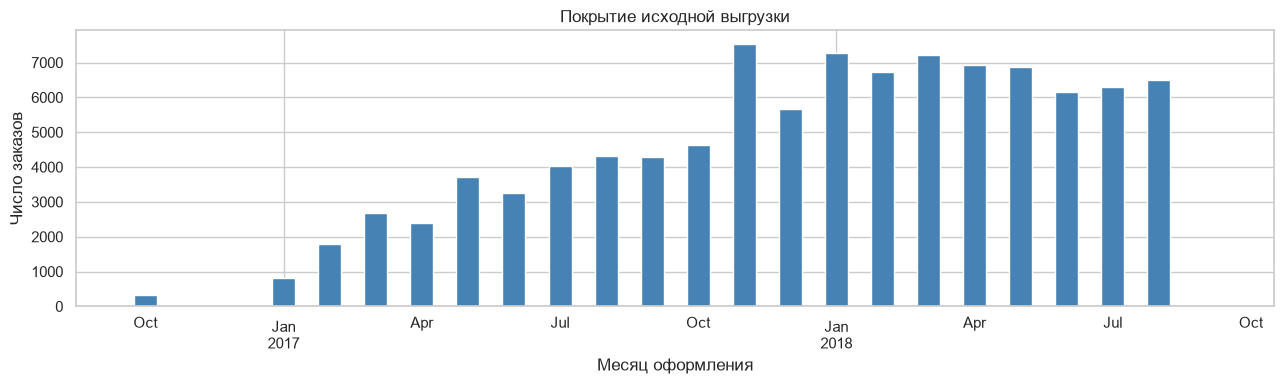

Основное окно заканчивается **2018-08**. За его пределами остаются **20** заказов. История до 2017 года сохранена для правильного определения первых наблюдаемых заказов.

In [3]:
coverage = pd.crosstab(events_all['order_month'], events_all['order_status'])
coverage = coverage.reindex(pd.period_range(events_all['order_month'].min(),
                                           events_all['order_month'].max(), freq='M'), fill_value=0)
coverage['total'] = coverage.sum(axis=1)
display(coverage)
ax = coverage['total'].plot.bar(figsize=(13, 4), color='steelblue')
ax.set(xlabel='Месяц оформления', ylabel='Число заказов', title='Покрытие исходной выгрузки')
show_plot('data_coverage')

events = events_all.loc[events_all['order_month'] <= OBS_END].copy()
excluded_tail = events_all.loc[events_all['order_month'] > OBS_END]
display(Markdown(f'Основное окно заканчивается **{OBS_END}**. За его пределами '
                 f'остаются **{len(excluded_tail)}** заказов. История до 2017 года '
                 'сохранена для правильного определения первых наблюдаемых заказов.'))


**Допущение о полноте:** август 2018 года принят последним полным месяцем.
За сентябрь и октябрь зарегистрированы только 16 и 4 заказа. Это аномалия покрытия,
но она сама по себе не доказывает остановку продукта или сбой выгрузки.
Полноту августа также нужно подтвердить у владельца данных; ниже проверяется
чувствительность к завершению анализа в июле и к включению сентября.

Редкие когорты 2016 года не удаляются из основного ответа «по всем когортам».
Отдельно показывается результат для когорт с января 2017 года. Первая покупка
означает **первую наблюдаемую**, поскольку история до начала выгрузки неизвестна.


## 1. Месячный retention в оформление заказа

**Событие:** оформление заказа любого статуса по `order_purchase_timestamp`.
Отмена впоследствии не удаляет факт оформления. Не требуется подтверждение оплаты.

**Когорта:** календарный месяц первого наблюдаемого оформления пользователя.
**Mk:** доля пользователей когорты, оформивших хотя бы один заказ в календарном месяце
через `k` месяцев после месяца первого заказа. M0 = 100%; повторные заказы внутри M0
не являются M1. Несколько заказов одного пользователя в месяц дают одно возвращение.

Знаменатель — исходный размер когорты, а не число активных в предыдущем месяце.
Это периодический retention: человек может пропустить M1 и вернуться в M2.

Наблюдаемый месяц без возвращений получает **0**; месяц после конца наблюдения —
**NaN**. Месяц без новых покупателей не образует когорту с нулевым знаменателем.


In [4]:
def calendar_retention(frame, end_month):
    """Полная календарная сетка: 0 для наблюдаемого отсутствия событий, NaN для будущего."""
    data = frame.loc[frame['order_purchase_timestamp'].dt.to_period('M') <= end_month,
                     ['customer_unique_id', 'order_purchase_timestamp']].copy()
    assert len(data) > 0
    data['month'] = data['order_purchase_timestamp'].dt.to_period('M')
    data['cohort'] = data.groupby('customer_unique_id')['month'].transform('min')
    data['age'] = data['month'].astype('int64') - data['cohort'].astype('int64')
    sizes = data.groupby('cohort')['customer_unique_id'].nunique().sort_index()
    ages = pd.Index(range(end_month.ordinal - sizes.index.min().ordinal + 1), name='age')
    counts = (data.groupby(['cohort', 'age'])['customer_unique_id'].nunique()
              .unstack('age').reindex(index=sizes.index, columns=ages).fillna(0))
    observed = pd.DataFrame(
        sizes.index.asi8[:, None] + ages.to_numpy()[None, :] <= end_month.ordinal,
        index=sizes.index, columns=ages)
    counts = counts.where(observed)
    retention = counts.div(sizes, axis=0)
    assert retention[0].eq(1).all()
    assert retention.stack().dropna().between(0, 1).all()
    assert counts.isna().equals(~observed)
    return retention, sizes, counts, data

# Содержательная проверка: дубль события не удваивает пользователя;
# пропущенный наблюдаемый месяц = 0; будущий месяц = NaN.
example = pd.DataFrame({
    'customer_unique_id': ['a', 'a', 'a', 'b', 'c', 'd'],
    'order_purchase_timestamp': pd.to_datetime([
        '2020-01-30', '2020-02-01', '2020-02-02', '2020-01-31', '2020-02-15', '2020-03-01'])})
test_r, test_s, _, _ = calendar_retention(example, pd.Period('2020-03', freq='M'))
assert test_r.loc['2020-01', 1] == 0.5
assert test_r.loc['2020-01', 2] == 0
assert test_r.loc['2020-02', 1] == 0
assert pd.isna(test_r.loc['2020-03', 1])

retention, cohort_size, cohort_counts, cohort_events = calendar_retention(events, OBS_END)
median_m1 = retention[1].median()
best_m3 = retention[3].idxmax()
best_m3_value = retention.loc[best_m3, 3]
display_percent(retention.iloc[:, :7], decimals=2)


age,0,1,2,3,4,5,6
cohort,,,,,,,
2016-09,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%
2016-10,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.31%
2016-12,100.00%,100.00%,0.00%,0.00%,0.00%,0.00%,0.00%
2017-01,100.00%,0.39%,0.26%,0.13%,0.39%,0.13%,0.52%
2017-02,100.00%,0.23%,0.29%,0.11%,0.40%,0.11%,0.23%
2017-03,100.00%,0.49%,0.38%,0.38%,0.34%,0.15%,0.15%
2017-04,100.00%,0.60%,0.21%,0.17%,0.34%,0.26%,0.34%
2017-05,100.00%,0.50%,0.50%,0.39%,0.31%,0.33%,0.42%
2017-06,100.00%,0.48%,0.35%,0.41%,0.25%,0.38%,0.38%


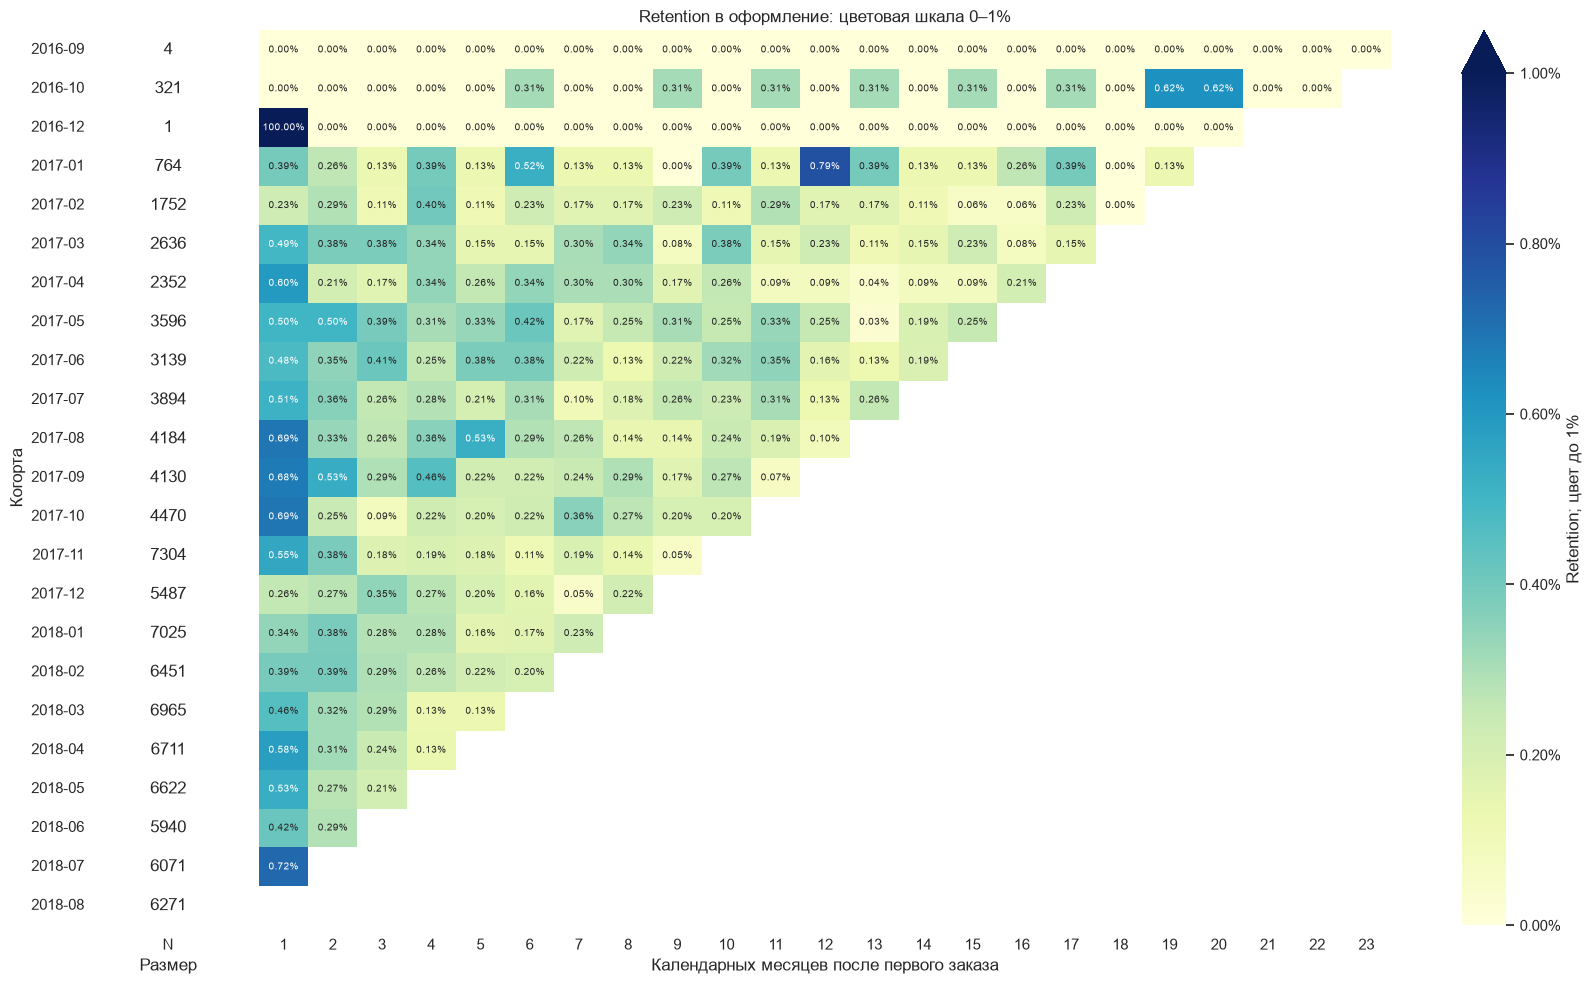

На карте **0,00%** означает отсутствие повторных оформлений, пустая ячейка — ненаблюдаемый период. Цвет ограничен 1%, а подписи показывают фактические значения. У когорты декабря 2016 M1 = 100%, но в ней всего один пользователь: это нестабильное значение не следует сравнивать с крупными когортами без учёта размера.

**Ответ:** медиана M1 по всем 22 наблюдаемым когортам — **0.497%**. Когорта с максимальным M3 — **2017-06**: **0.414%**, 13 вернувшихся из 3139. Это описательный максимум, а не доказанное превосходство когорты.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 10), sharey=True,
                         gridspec_kw={'width_ratios': [1.2, 12]})
sns.heatmap(cohort_size.to_frame('N'), annot=True, fmt='g', cbar=False,
            cmap=mcolors.ListedColormap(['white']), ax=axes[0])
axes[0].set(xlabel='Размер', ylabel='Когорта')
sns.heatmap(retention.drop(columns=0), mask=retention.drop(columns=0).isna(),
            annot=True, fmt='.2%', cmap='YlGnBu', vmin=0, vmax=0.01,
            annot_kws={'fontsize': 7}, ax=axes[1],
            cbar_kws={'format': PercentFormatter(1), 'extend': 'max', 'label': 'Retention; цвет до 1%'})
axes[1].set(xlabel='Календарных месяцев после первого заказа', ylabel='',
            title='Retention в оформление: цветовая шкала 0–1%')
axes[0].grid(False)
axes[1].grid(False)
show_plot('retention_heatmap')

display(Markdown('На карте **0,00%** означает отсутствие повторных оформлений, '
                 'пустая ячейка — ненаблюдаемый период. Цвет ограничен 1%, '
                 'а подписи показывают фактические значения. У когорты декабря 2016 '
                 'M1 = 100%, но в ней всего один пользователь: это нестабильное значение '
                 'не следует сравнивать с крупными когортами без учёта размера.'))
display(Markdown(
    f'**Ответ:** медиана M1 по всем {retention[1].notna().sum()} наблюдаемым когортам '
    f'— **{median_m1:.3%}**. Когорта с максимальным M3 — **{best_m3}**: '
    f'**{best_m3_value:.3%}**, '
    f'{int(cohort_counts.loc[best_m3, 3])} вернувшихся из {int(cohort_size.loc[best_m3])}. '
    'Это описательный максимум, а не доказанное превосходство когорты.'))


### Проверка чувствительности

Сравним статусы, включение ранних когорт и границу наблюдения. При смене события
когорта также пересчитывается по первому событию соответствующего вида.
Для варианта «с 2017 года» фильтруются **уже определённые когорты**: старый покупатель
не становится новым из-за удаления его прежних заказов.


In [6]:
definitions = {
    'Все оформления': events,
    'Подтверждена оплата, без canceled': events.loc[
        events['order_approved_at'].notna() & events['order_status'].ne('canceled')],
    'Впоследствии доставленные': events.loc[events['order_status'].eq('delivered')],
}
sensitivity_rows = []
for name, frame in definitions.items():
    matrix, sizes, _, _ = calendar_retention(frame, OBS_END)
    for label, selected in [('Все когорты', matrix),
                            ('Когорты с 2017-01', matrix.loc[matrix.index >= METRICS_START])]:
        sensitivity_rows.append({'event': name, 'cohorts': label,
            'n_M1': selected[1].notna().sum(), 'median_M1': selected[1].median(),
            'best_M3_cohort': str(selected[3].idxmax()), 'best_M3': selected[3].max()})
sensitivity = pd.DataFrame(sensitivity_rows)
display_percent(sensitivity, ['median_M1', 'best_M3'])

boundary_rows = []
for end in pd.period_range('2018-07', '2018-09', freq='M'):
    matrix, _, _, _ = calendar_retention(events_all, end)
    boundary_rows.append({'end_month': str(end), 'n_M1': matrix[1].notna().sum(),
                           'median_M1': matrix[1].median(),
                           'note': 'Основное допущение' if end == OBS_END else
                           ('Неполнота вероятна — диагностический сценарий' if end > OBS_END else 'Консервативная граница')})
boundary = pd.DataFrame(boundary_rows)
display_percent(boundary, ['median_M1'])


,event,cohorts,n_M1,median_M1,best_M3_cohort,best_M3
0,Все оформления,Все когорты,22,0.497%,2017-06,0.414%
1,Все оформления,Когорты с 2017-01,19,0.501%,2017-06,0.414%
2,"Подтверждена оплата, без canceled",Все когорты,22,0.488%,2017-06,0.416%
3,"Подтверждена оплата, без canceled",Когорты с 2017-01,19,0.499%,2017-06,0.416%
4,Впоследствии доставленные,Все когорты,22,0.479%,2017-06,0.428%
5,Впоследствии доставленные,Когорты с 2017-01,19,0.494%,2017-06,0.428%


,end_month,n_M1,median_M1,note
0,2018-07,21,0.493%,Консервативная граница
1,2018-08,22,0.497%,Основное допущение
2,2018-09,23,0.493%,Неполнота вероятна — диагностический сценарий


## 2. Product/market fit и возможные направления исследования

На длинных горизонтах доступны только старые когорты. Чтобы изменение состава когорт
не выглядело изменением удержания, сравниваем M1–M6 на **одних и тех же когортах**
с января 2017 года, для которых полностью наблюдаем M6. Медиана даёт равный вес
когортам, взвешенная доля — покупателям. Это разные сводные показатели.


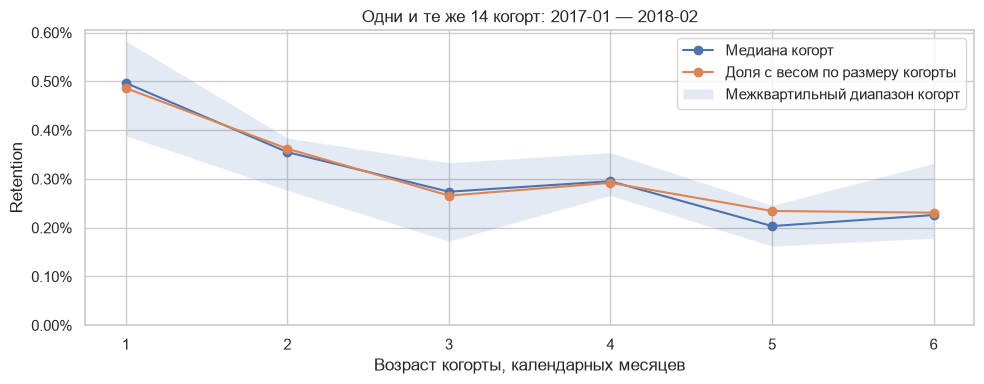

,median,weighted,q25,q75
age,,,,
1,0.497%,0.486%,0.389%,0.583%
2,0.355%,0.362%,0.276%,0.384%
3,0.274%,0.266%,0.172%,0.333%
4,0.295%,0.292%,0.266%,0.354%
5,0.203%,0.234%,0.162%,0.246%
6,0.226%,0.231%,0.178%,0.332%


За всё доступное основное окно **96.89%** пользователей имеют только одно оформление. У них разная длительность наблюдения: это не оценка окончательного оттока. На фиксированных когортах медианная доля вернувшихся хотя бы раз в M1–M6 составляет **1.79%**. Повторы в месяц первого заказа сюда не входят.

In [7]:
common_index = retention.index[(retention.index >= METRICS_START) & retention[6].notna()]
common = retention.loc[common_index, list(range(1, 7))]
retention_curve = pd.DataFrame({
    'median': common.median(),
    'weighted': cohort_counts.loc[common_index, list(range(1, 7))].sum() / cohort_size.loc[common_index].sum(),
    'q25': common.quantile(0.25), 'q75': common.quantile(0.75),
})
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(retention_curve.index, retention_curve['median'], marker='o', label='Медиана когорт')
ax.plot(retention_curve.index, retention_curve['weighted'], marker='o', label='Доля с весом по размеру когорты')
ax.fill_between(retention_curve.index, retention_curve['q25'], retention_curve['q75'],
                 alpha=0.15, label='Межквартильный диапазон когорт')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Возраст когорты, календарных месяцев', ylabel='Retention', ylim=(0, None),
       title=f'Одни и те же {len(common_index)} когорт: {common_index.min()} — {common_index.max()}')
ax.legend()
show_plot('retention_common_cohorts')
display_percent(retention_curve)

# Вернулся хотя бы в одном из месяцев M1–M6. Не сумма месячного retention.
cumulative_users = (cohort_events.loc[cohort_events['cohort'].isin(common_index)
                                     & cohort_events['age'].between(1, 6)]
                    .groupby('cohort')['customer_unique_id'].nunique().reindex(common_index, fill_value=0))
cumulative_6 = cumulative_users / cohort_size.loc[common_index]
order_frequency = events.groupby('customer_unique_id')['order_id'].nunique()
single_share = order_frequency.eq(1).mean()
display(Markdown(
    f'За всё доступное основное окно **{single_share:.2%}** пользователей имеют только '
    'одно оформление. У них разная длительность наблюдения: это не оценка окончательного оттока. '
    f'На фиксированных когортах медианная доля вернувшихся хотя бы раз в M1–M6 '
    f'составляет **{cumulative_6.median():.2%}**. Повторы в месяц первого заказа сюда не входят.'))


**Вывод о PMF:** повторные оформления редки, поэтому удержание требует исследования.
Данных недостаточно, чтобы однозначно объявить отсутствие PMF, объяснить поведение
неудовлетворённостью или принять решение о масштабировании. Здесь нет посещений без
покупки, категорий товаров, каналов привлечения и оценки экономики.

В ближайшее время нужно подтвердить полноту истории, изучить повторные покупки
по категориям и естественному циклу спроса, собрать обратную связь и проверить причины
отмен. Программы лояльности и ускорение доставки — гипотезы для проверки,
а не доказанные способы роста. Дата первого заказа в выгрузке не устанавливает дату
запуска бизнеса, а рост когорт не устанавливает факт маркетинговой кампании.


### Диагностика доставки и стоимости заказа

Для этапов доставки считаются фактические интервалы в дробных сутках. Пропуски
сохраняются как NaN; отрицательные интервалы отмечаются и исключаются только из
статистики соответствующего этапа. Мы не превращаем даты с NaT в целые числа.

Опоздание — фактическая **календарная дата** позже обещанной. Доставка в обещанный
день считается своевременной. Анализ относится к оформленным до границы окна заказам
с известным статусом `delivered`, даже если доставлены они позднее августа.


,valid_n,missing_n,negative_n,mean_days,median_days,p75_days,p90_days
stage,,,,,,,
Оформление → подтверждение,96464,14,0,0.4300,0.0100,0.6000,1.4400
Подтверждение → перевозчик,95112,16,1350,2.8500,1.8500,3.6200,6.0200
Перевозчик → доставка,96446,9,23,9.3300,7.1000,12.0300,18.9000
Оформление → доставка,96470,8,0,12.5600,10.2200,15.7200,23.1000


Из **96,470** доставленных заказов с известными датами опоздали **6.77%**. У **8** доставленных заказов даты для сравнения отсутствуют.

,orders,median_days,p90_days
customer_state,,,
AM,145,25.8800,39.1300
RR,41,25.0100,53.1900
AP,67,24.3500,34.6600
AL,397,22.3300,39.4500
PA,946,21.0800,39.2300
MA,717,19.1900,34.3200
AC,80,18.3600,31.0800
CE,1279,18.2100,34.7200
PB,517,18.1500,34.9500


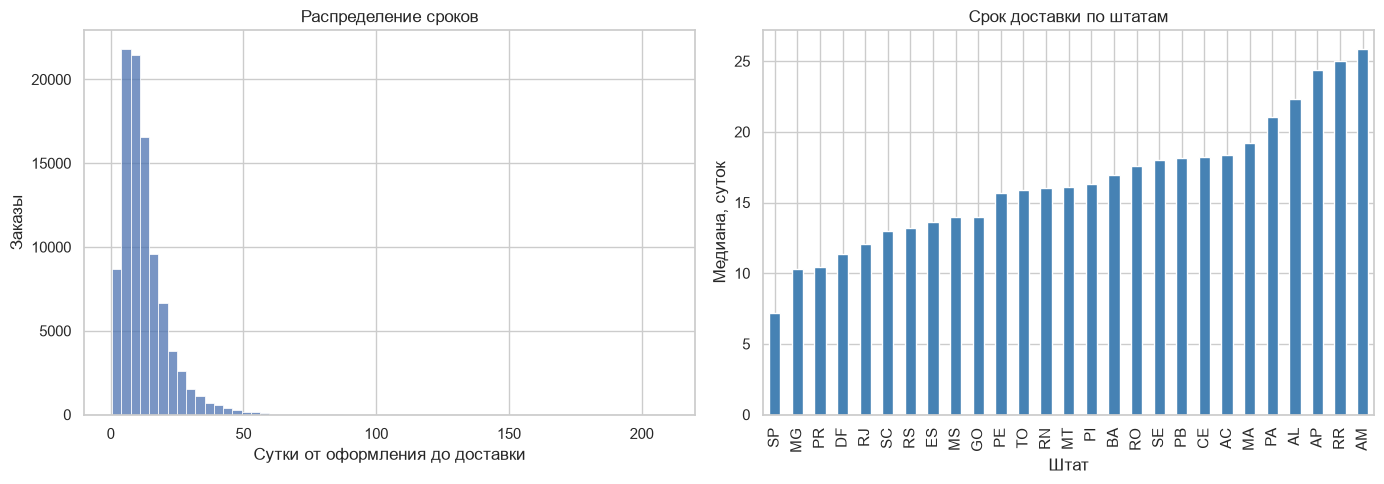

Средний чек доставленного заказа без доставки: **137.04 BRL**. Доля доставленных заказов с одной товарной позицией: **90.01%**. Доля отменённых/недоступных заказов среди всех оформлений: **1.22%**. **Это не доля возвратов товаров.**

In [8]:
delivered = events.loc[events['order_status'].eq('delivered')].copy()
stage_pairs = {
    'Оформление → подтверждение': ('order_purchase_timestamp', 'order_approved_at'),
    'Подтверждение → перевозчик': ('order_approved_at', 'order_delivered_carrier_date'),
    'Перевозчик → доставка': ('order_delivered_carrier_date', 'order_delivered_customer_date'),
    'Оформление → доставка': ('order_purchase_timestamp', 'order_delivered_customer_date'),
}
delivery_rows = []
for label, (start, finish) in stage_pairs.items():
    interval = (delivered[finish] - delivered[start]).dt.total_seconds() / 86400
    valid = interval.loc[interval.ge(0)]
    delivery_rows.append({'stage': label, 'valid_n': len(valid), 'missing_n': interval.isna().sum(),
        'negative_n': interval.lt(0).sum(), 'mean_days': valid.mean(), 'median_days': valid.median(),
        'p75_days': valid.quantile(0.75), 'p90_days': valid.quantile(0.9)})
delivery_summary = pd.DataFrame(delivery_rows).set_index('stage')
display(delivery_summary.round(2))

delivered['delivery_days'] = (delivered['order_delivered_customer_date'] -
                              delivered['order_purchase_timestamp']).dt.total_seconds() / 86400
delivered['promise_delta_days'] = (delivered['order_delivered_customer_date'].dt.normalize() -
                                   delivered['order_estimated_delivery_date'].dt.normalize()).dt.days
known_delivery = delivered.loc[delivered['promise_delta_days'].notna()]
late_share = known_delivery['promise_delta_days'].gt(0).mean()
display(Markdown(f'Из **{len(known_delivery):,}** доставленных заказов с известными датами '
                 f'опоздали **{late_share:.2%}**. У **{len(delivered)-len(known_delivery)}** '
                 'доставленных заказов даты для сравнения отсутствуют.'))

state_delivery = (delivered.loc[delivered['delivery_days'].ge(0)]
                  .groupby('customer_state').agg(orders=('order_id', 'nunique'),
                       median_days=('delivery_days', 'median'),
                       p90_days=('delivery_days', lambda s: s.quantile(0.9))))
display(state_delivery.sort_values('median_days', ascending=False).round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(delivered.loc[delivered['delivery_days'].ge(0), 'delivery_days'], bins=60, ax=axes[0])
axes[0].set(xlabel='Сутки от оформления до доставки', ylabel='Заказы', title='Распределение сроков')
state_delivery.sort_values('median_days')['median_days'].plot.bar(ax=axes[1], color='steelblue')
axes[1].set(xlabel='Штат', ylabel='Медиана, суток', title='Срок доставки по штатам')
show_plot('delivery_diagnostics')

order_values = items.groupby('order_id').agg(order_value=('price', 'sum'), item_count=('order_item_id', 'count'))
delivered_values = delivered.merge(order_values, on='order_id', how='left', validate='one_to_one')
assert delivered_values['order_value'].notna().all()
average_order_value = delivered_values['order_value'].mean()
cancellation_share = events['order_status'].isin(['canceled', 'unavailable']).mean()
display(Markdown(
    f'Средний чек доставленного заказа без доставки: **{average_order_value:.2f} BRL**. '
    f'Доля доставленных заказов с одной товарной позицией: '
    f'**{delivered_values["item_count"].eq(1).mean():.2%}**. '
    f'Доля отменённых/недоступных заказов среди всех оформлений: **{cancellation_share:.2%}**. '
    '**Это не доля возвратов товаров.**'))


Своевременность относительно обещания и удовлетворённость скоростью — разные вопросы.
Высокая доля доставок до обещанного дня не исключает проблем клиентского опыта.
Различия по штатам описательны: без учёта ассортимента, продавцов, расстояний и стоимости
нельзя приписать им причинное влияние на retention или обосновать строительство складов.
Финальные статусы доставок зависят от времени выгрузки; последние месяцы могут ещё дозревать.


## 3. Пять основных метрик

| Задача метрики | Метрика и определение | Доступность |
|---|---|---|
| Объём продаж | GMV доставленных заказов: сумма `price` всех позиций | Рассчитано; без доставки |
| Аудитория, получившая товар | Уникальные покупатели доставленных заказов за месяц | Рассчитано; это не все посетители |
| Интерес новых пользователей | Новые посетители с первой покупкой / все новые посетители, с одинаковым окном конверсии | Нет данных о посетителях |
| Продолжение использования | Retention в оформление по календарным когортам | Рассчитано в разделе 1 |
| Денежная активность покупателя | GMV / уникальные покупатели доставленных заказов | Рассчитано; это не ARPPU площадки |

Месяц денежных показателей определяется по **оформлению** заказа, который в итоге
доставлен, а не по дате поступления денег. GMV не равен комиссии, выручке или прибыли
площадки. Для цели максимизации прибыли дополнительно нужны комиссия, маржа, расходы
на привлечение, логистику и обслуживание. Ни один из этих показателей не придумывается.

Графики с января 2017 года исключают редкие стартовые месяцы только из представления
динамики; это не меняет историю для определения когорт.


,gmv,buyers,orders,gmv_per_buyer,average_order_value
2017-01,"111,798.3600",718,750,155.7100,149.0600
2017-02,"234,223.4000",1630,1653,143.7000,141.7000
2017-03,"359,198.8500",2508,2546,143.2200,141.0800
2017-04,"340,669.6800",2274,2303,149.8100,147.9200
2017-05,"489,338.2500",3479,3546,140.6500,138.0000
2017-06,"421,923.3700",3076,3135,137.1700,134.5800
2017-07,"481,604.5200",3802,3872,126.6700,124.3800
2017-08,"554,699.7000",4114,4193,134.8300,132.2900
2017-09,"607,399.6700",4083,4150,148.7600,146.3600
2017-10,"648,247.6500",4417,4478,146.7600,144.7600


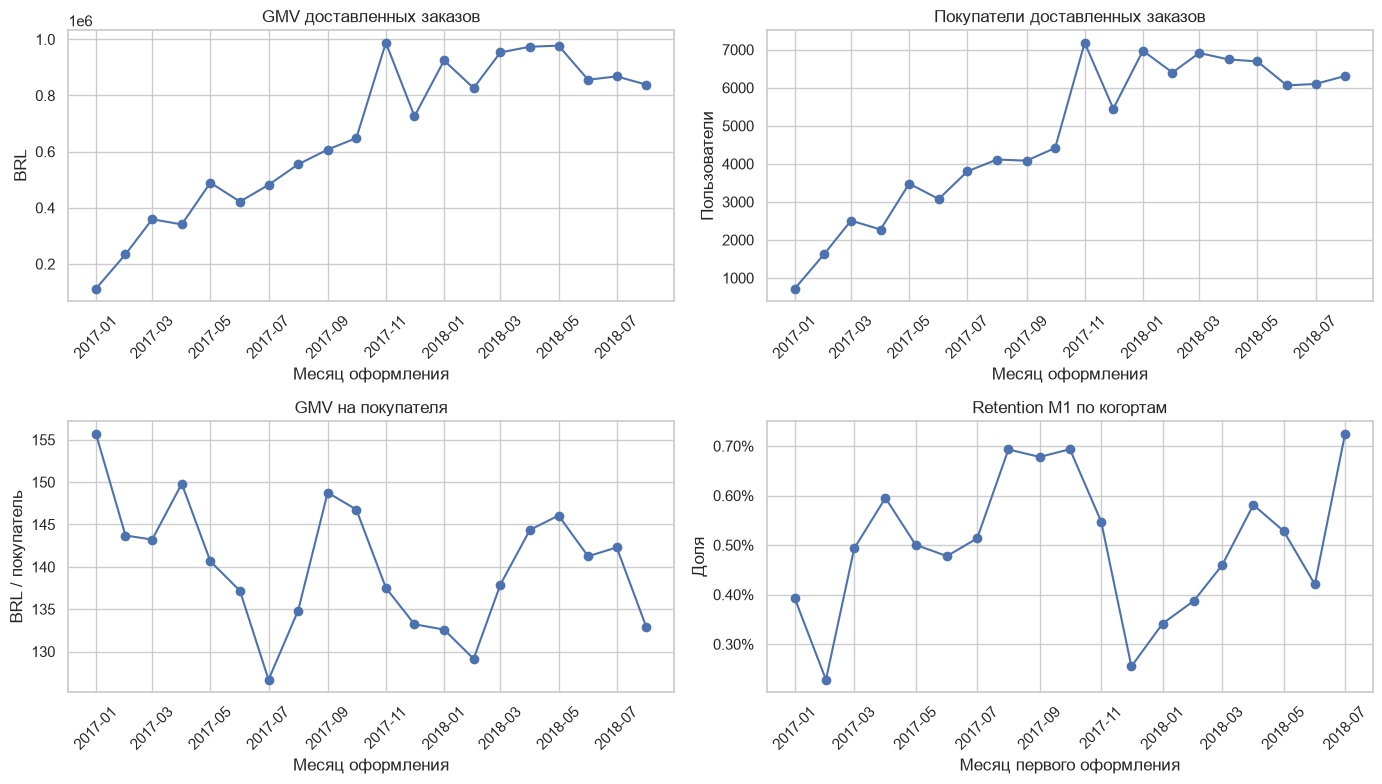

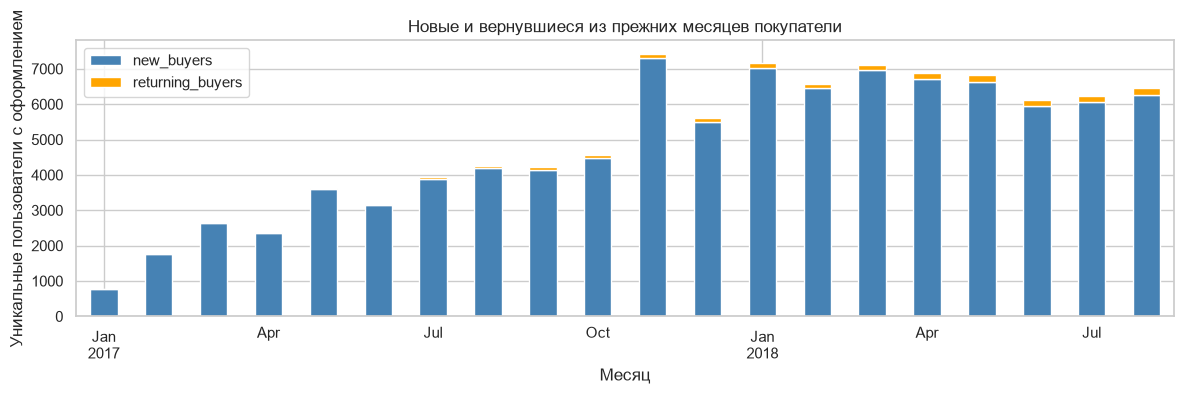

In [9]:
metric_months = pd.period_range(METRICS_START, OBS_END, freq='M')
monthly_metrics = delivered_values.groupby('order_month').agg(
    gmv=('order_value', 'sum'), buyers=('customer_unique_id', 'nunique'),
    orders=('order_id', 'nunique'))
monthly_metrics = monthly_metrics.reindex(metric_months)
assert monthly_metrics[['gmv', 'buyers', 'orders']].notna().all().all()
monthly_metrics['gmv_per_buyer'] = monthly_metrics['gmv'] / monthly_metrics['buyers']
monthly_metrics['average_order_value'] = monthly_metrics['gmv'] / monthly_metrics['orders']
assert np.allclose(monthly_metrics['gmv_per_buyer'] * monthly_metrics['buyers'], monthly_metrics['gmv'])
display(monthly_metrics.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col, title, unit in [
    (axes[0, 0], 'gmv', 'GMV доставленных заказов', 'BRL'),
    (axes[0, 1], 'buyers', 'Покупатели доставленных заказов', 'Пользователи'),
    (axes[1, 0], 'gmv_per_buyer', 'GMV на покупателя', 'BRL / покупатель')]:
    ax.plot(monthly_metrics.index.to_timestamp(), monthly_metrics[col], marker='o')
    ax.set(title=title, ylabel=unit, xlabel='Месяц оформления')
    ax.tick_params(axis='x', rotation=45)
m1_series = retention.loc[retention.index >= METRICS_START, 1]
axes[1, 1].plot(m1_series.index.to_timestamp(), m1_series, marker='o')
axes[1, 1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1, 1].set(title='Retention M1 по когортам', xlabel='Месяц первого оформления', ylabel='Доля')
axes[1, 1].tick_params(axis='x', rotation=45)
show_plot('business_metrics')

# Доли пользователей, а не число повторных заказов / число пользователей.
first_month = events.groupby('customer_unique_id')['order_month'].min()
buyer_months = events[['customer_unique_id', 'order_month']].drop_duplicates()
buyer_months['returning'] = buyer_months['order_month'] > buyer_months['customer_unique_id'].map(first_month)
monthly_audience = buyer_months.groupby('order_month').agg(
    active_buyers=('customer_unique_id', 'nunique'), returning_buyers=('returning', 'sum'))
monthly_audience['new_buyers'] = monthly_audience['active_buyers'] - monthly_audience['returning_buyers']
monthly_audience['returning_share'] = monthly_audience['returning_buyers'] / monthly_audience['active_buyers']
assert monthly_audience['returning_share'].between(0, 1).all()
monthly_audience.loc[METRICS_START:, ['new_buyers', 'returning_buyers']].plot.bar(
    stacked=True, figsize=(12, 4), color=['steelblue', 'orange'])
plt.ylabel('Уникальные пользователи с оформлением')
plt.xlabel('Месяц')
plt.title('Новые и вернувшиеся из прежних месяцев покупатели')
show_plot('new_and_returning_buyers')


Доля вернувшихся среди активных пользователей — дополнительная диагностика состава
аудитории, а не когортный retention. У этих показателей разные знаменатели.
Покупатель с несколькими заказами в месяц учитывается один раз.


## 4. Приоритизация гипотез по ICE

Период основного сценария: **июнь 2017 — август 2018**. Сентябрь–октябрь исключены
по тому же правилу полноты, что и остальные расчёты. Для сопоставления с условием
ниже отдельно показан сценарий по всем доступным записям с июня 2017 года.

По условию конверсия в повторный заказ принимается равной рассчитанной медиане M1.
Она используется без предварительного округления. Это учебная сценарная модель:
наблюдаемый retention сам по себе не является причинным приростом от изменения.
Для H2/H3 предполагается, что каждый из выбранных пользователей с вероятностью `p`
совершит **один дополнительный** заказ. Реальный эффект проверяется экспериментом.

1. **H1 — исправить процессинг.** По условию устраняются все отмены: `canceled` и
   `unavailable`. Прямой эффект равен числу таких заказов. Повторы сверх него не
   добавляются. Принадлежность всех отмен одному багу принимается только как допущение задания.
2. **H2 — сократить время до отгрузки.** База — уникальные покупатели доставленных
   с опозданием заказов; эффект = покупатели × `p`. Доставка в обещанный день не опоздание.
3. **H3 — новый способ оплаты.** База — пользователи с ровно одним оформлением за всю
   доступную историю до границы окна, причём этот заказ доставлен и оформлен с июня 2017.
   Наличие более раннего заказа проверяется до фильтра по июню. Такой выбор соответствует
   покупателям, ещё не оформившим повторный заказ; причины отсутствия повтора неизвестны.

Одинаковый будущий горизонт наблюдения этих пользователей историческая выборка не
обеспечивает. Это ещё одна причина трактовать Impact как сценарий, а не прогноз.


In [10]:
# Шкала предоставлена в условии пользователем, не восстановлена по примерам.
impact_upper = np.array([50, 150, 350, 750, 1550, 3150, 6350, 12750, 25550, 51150])
impact_scale = pd.DataFrame({'Impact': range(1, 11),
    'Интервал числа заказов': ['0–50', '51–150', '151–350', '351–750', '751–1550',
        '1551–3150', '3151–6350', '6351–12750', '12751–25550', '25551–51150']})
display(impact_scale)

def impact_score(expected_orders):
    # Модель даёт дробное ожидание. Для целочисленной шкалы округляем до ближайшего заказа.
    rounded = int(np.floor(float(expected_orders) + 0.5))
    assert 0 <= rounded <= impact_upper[-1]
    return int(np.searchsorted(impact_upper, rounded, side='left') + 1)

assert [impact_score(x) for x in [0, 50, 51, 150, 151, 350, 351, 750, 751]] == [1,1,2,2,3,3,4,4,5]

def hypothesis_effects(history, probability):
    recent = history.loc[history['order_month'] >= HYPOTHESIS_START]
    canceled = recent.loc[recent['order_status'].isin(['canceled', 'unavailable'])]
    successful = recent.loc[recent['order_status'].eq('delivered')]
    delayed = successful.loc[successful['order_delivered_customer_date'].dt.normalize()
                             > successful['order_estimated_delivery_date'].dt.normalize()]
    counts = history.groupby('customer_unique_id')['order_id'].nunique()
    single_users = counts.index[counts.eq(1)]
    h3_users = successful.loc[successful['customer_unique_id'].isin(single_users), 'customer_unique_id'].nunique()
    bases = [canceled['order_id'].nunique(), delayed['customer_unique_id'].nunique(), h3_users]
    result = pd.DataFrame({
        'hypothesis': ['H1: процессинг', 'H2: отгрузка', 'H3: оплата'],
        'base': bases, 'unit': ['заказы', 'пользователи', 'пользователи'],
        'expected_orders': [bases[0], bases[1] * probability, bases[2] * probability],
        'Confidence': [8, 10, 5], 'Ease': [6, 4, 9],
    }).set_index('hypothesis')
    result['Impact'] = result['expected_orders'].map(impact_score)
    result['ICE'] = result['Impact'] * result['Confidence'] * result['Ease']
    return result

ice = hypothesis_effects(events, median_m1)
display(Markdown(f'Конверсия из раздела 1: **{median_m1:.4%}**.'))
display(ice)

ice_full = hypothesis_effects(events_all, median_m1)
display(Markdown('**Проверка по всем доступным записям с июня 2017 (включая редкий хвост):** '
                 'конверсию оставляем прежней, меняем только историческую базу сценария.'))
display(ice_full)
winner = ice['ICE'].idxmax()
display(Markdown(f'При выбранных допущениях приоритет — **{winner}**, ICE = '
                 f'**{ice.loc[winner, "ICE"]}**. '
                 'Рейтинг не доказывает причинный эффект; оценки Confidence/Ease взяты из условия.'))

# Как изменится рейтинг при альтернативных определениях retention?
ice_sensitivity = []
for name, frame in definitions.items():
    matrix, _, _, _ = calendar_retention(frame, OBS_END)
    probability = matrix[1].median()
    scores = hypothesis_effects(events, probability)
    ice_sensitivity.append({'retention_event': name, 'p': probability,
        'H1_ICE': scores.iloc[0]['ICE'], 'H2_ICE': scores.iloc[1]['ICE'],
        'H3_ICE': scores.iloc[2]['ICE'], 'winner': scores['ICE'].idxmax()})
display_percent(pd.DataFrame(ice_sensitivity), ['p'])


,Impact,Интервал числа заказов
0,1,0–50
1,2,51–150
2,3,151–350
3,4,351–750
4,5,751–1550
5,6,1551–3150
6,7,3151–6350
7,8,6351–12750
8,9,12751–25550
9,10,25551–51150


Конверсия из раздела 1: **0.4969%**.

,base,unit,expected_orders,Confidence,Ease,Impact,ICE
hypothesis,,,,,,,
H1: процессинг,955,заказы,955.0000,8,6,5,240
H2: отгрузка,6054,пользователи,30.0801,10,4,1,40
H3: оплата,80127,пользователи,398.1221,5,9,4,180


**Проверка по всем доступным записям с июня 2017 (включая редкий хвост):** конверсию оставляем прежней, меняем только историческую базу сценария.

,base,unit,expected_orders,Confidence,Ease,Impact,ICE
hypothesis,,,,,,,
H1: процессинг,974,заказы,974.0000,8,6,5,240
H2: отгрузка,6054,пользователи,30.0801,10,4,1,40
H3: оплата,80120,пользователи,398.0873,5,9,4,180


При выбранных допущениях приоритет — **H1: процессинг**, ICE = **240**. Рейтинг не доказывает причинный эффект; оценки Confidence/Ease взяты из условия.

,retention_event,p,H1_ICE,H2_ICE,H3_ICE,winner
0,Все оформления,0.497%,240,40,180,H1: процессинг
1,"Подтверждена оплата, без canceled",0.488%,240,40,180,H1: процессинг
2,Впоследствии доставленные,0.479%,240,40,180,H1: процессинг


## 5. Метрики эксперимента для исправления процессинга

**Дизайн:** пользователи случайно и устойчиво распределяются в контроль и тест до
воздействия изменения. Единица анализа — пользователь; учитываются все назначенные
пользователи, включая не оформивших заказ. Сравниваются одновременные группы,
а не показатели «после минус до». Период включения заказов и одинаковое время ожидания
их исходов фиксируются до запуска. Длительность зависит от распределения доставки;
незавершённые заказы нельзя автоматически объявлять успешными или отменёнными.

| Роль | Метрика | Зачем нужна |
|---|---|---|
| Целевая | Число доставленных заказов, оформленных в окне эксперимента, / число назначенных пользователей | Проверяет общий эффект на успешные заказы при сопоставимом размере аудитории |
| Прокси | Доля созданных заказов с зарегистрированной ошибкой процессинга | Быстро проверяет исправляемый механизм; требуется журнал ошибок и согласованное определение |
| Диагностика прокси | Доля `canceled` / `unavailable` среди созданных заказов, отдельно по причинам | Доступнее, но не все такие статусы означают исправляемый баг; нужен одинаковый срок наблюдения |
| Guardrail | Пользователи с хотя бы одним оформлением / назначенные пользователи | Не ухудшилось ли оформление |
| Guardrail | Доля заказов с просроченным обещанием: доставленных поздно либо ещё не доставленных после обещанного дня | Контролирует нагрузку на доставку; сравнивать заказы, для которых срок уже наступил |
| Guardrail | Обращения в поддержку / назначенные пользователи | Не переносит ли исправление проблему на другие этапы; нужны данные поддержки |
| Guardrail | Возвращённые товары/заказы / доставленные заказы с полным окном возврата | Контролирует качество результата; данных о возвратах в текущей выгрузке нет |

Статистическую неопределённость оценивают на уровне единицы рандомизации, учитывая
несколько заказов одного пользователя. MDE, размер выборки, пороги допустимого
ухудшения и критерий остановки задаются заранее. По этим CSV нельзя рассчитать
эффект A/B-теста: нет назначения в группы и событий процессинга.


## 6. Итоги

Соберём основные результаты и следующие шаги.


In [11]:
peak_month = monthly_metrics['gmv'].idxmax()
latest = monthly_metrics.iloc[-1]
stage_median = delivery_summary.loc['Оформление → доставка', 'median_days']
report = f"""# Итоги анализа маркетплейса

## Определения и границы

Основной период заканчивается {OBS_END}; полнота этого месяца — допущение,
требующее подтверждения. Редкие записи сентября–октября исключены из основных
показателей. История до 2017 года сохранена для определения первых наблюдаемых заказов.
Retention считается по всем оформлениям, календарным месяцам и customer_unique_id.
Нули отличаются от ещё не наблюдаемых периодов. Денежные метрики — по заказам,
которые впоследствии доставлены, в месяце оформления, без стоимости доставки.

## Результаты

- Медиана retention M1 по всем {retention[1].notna().sum()} наблюдаемым когортам: **{median_m1:.3%}**.
- Максимальный M3: **{best_m3}, {best_m3_value:.3%}** — {int(cohort_counts.loc[best_m3, 3])} из {int(cohort_size.loc[best_m3])} пользователей.
- На фиксированном наборе {len(common_index)} когорт медианная доля пользователей,
  вернувшихся хотя бы раз в M1–M6: **{cumulative_6.median():.2%}**.
- Одно оформление за доступную историю имеют **{single_share:.2%}** пользователей;
  это описательная доля при разной длительности наблюдения, не окончательный отток.
- GMV достиг максимума в **{peak_month}**: **{monthly_metrics.loc[peak_month, 'gmv']:,.2f} BRL**.
  В {OBS_END}: **{latest['gmv']:,.2f} BRL**, **{int(latest['buyers']):,}** покупателей
  доставленных заказов, **{latest['gmv_per_buyer']:.2f} BRL** GMV на покупателя.
- Средний чек доставленного заказа: **{average_order_value:.2f} BRL**.
- Медиана оформления → доставки: **{stage_median:.2f} суток**.
  Доля опозданий среди доставленных заказов с известными датами: **{late_share:.2%}**.
- Доля canceled/unavailable: **{cancellation_share:.2%}**. Это отмены, а не возвраты товаров.

## Интерпретация

Повторные оформления редки. Это сигнал для исследования удержания, но не доказательство
отсутствия PMF или неудовлетворённости покупателей. Причины стабилизации GMV не установлены
причинно. Прибыль и собственная выручка площадки неизвестны без комиссий и затрат.
Своевременная доставка не исключает недовольства её абсолютной длительностью.

## ICE по шкале из условия

Использована конверсия {median_m1:.4%}, без преждевременного округления.

"""
for name, row in ice.iterrows():
    report += (f"- {name}: сценарный эффект {row['expected_orders']:.2f} заказов; "
               f"Impact {row['Impact']}, Confidence {row['Confidence']}, "
               f"Ease {row['Ease']}, **ICE {row['ICE']}**.\n")
report += f"""

Приоритет в заданной модели — **{winner}**. Устранение всех отмен — допущение условия,
а не установленная причина всех отмен. Для H2/H3 вероятность повторного оформления
используется как сценарная вероятность одного дополнительного заказа; это не оценка
реального прироста. Полная история и чувствительность представлены в ноутбуке.

## Следующие действия

1. Подтвердить полноту выгрузки и устойчивость идентификатора покупателя.
2. Проверить причины отмен и журнал ошибок, затем экспериментально проверить исправление процессинга.
3. Контролировать доставленные заказы на назначенного пользователя, ошибки процессинга,
   конверсию в оформление, просроченные заказы, поддержку и возвраты.
4. Получить категории товаров, каналы привлечения и обратную связь; проверить удержание
   на горизонтах, соответствующих естественной частоте покупок.
5. Добавить данные о комиссиях и затратах, прежде чем делать выводы о прибыльности и масштабировании.

## Проверки

Проверены ключи таблиц и связи, отсутствие размножения заказов при объединении,
границы retention, различие 0/NaN, дедупликация пользователей в месяце,
календарный переход месяца на небольшом примере и границы шкалы Impact.
Все кодовые ячейки должны выполняться последовательно в новой сессии.
"""
display(Markdown(report))


# Итоги анализа маркетплейса

## Определения и границы

Основной период заканчивается 2018-08; полнота этого месяца — допущение,
требующее подтверждения. Редкие записи сентября–октября исключены из основных
показателей. История до 2017 года сохранена для определения первых наблюдаемых заказов.
Retention считается по всем оформлениям, календарным месяцам и customer_unique_id.
Нули отличаются от ещё не наблюдаемых периодов. Денежные метрики — по заказам,
которые впоследствии доставлены, в месяце оформления, без стоимости доставки.

## Результаты

- Медиана retention M1 по всем 22 наблюдаемым когортам: **0.497%**.
- Максимальный M3: **2017-06, 0.414%** — 13 из 3139 пользователей.
- На фиксированном наборе 14 когорт медианная доля пользователей,
  вернувшихся хотя бы раз в M1–M6: **1.79%**.
- Одно оформление за доступную историю имеют **96.89%** пользователей;
  это описательная доля при разной длительности наблюдения, не окончательный отток.
- GMV достиг максимума в **2017-11**: **987,765.37 BRL**.
  В 2018-08: **838,576.64 BRL**, **6,310** покупателей
  доставленных заказов, **132.90 BRL** GMV на покупателя.
- Средний чек доставленного заказа: **137.04 BRL**.
- Медиана оформления → доставки: **10.22 суток**.
  Доля опозданий среди доставленных заказов с известными датами: **6.77%**.
- Доля canceled/unavailable: **1.22%**. Это отмены, а не возвраты товаров.

## Интерпретация

Повторные оформления редки. Это сигнал для исследования удержания, но не доказательство
отсутствия PMF или неудовлетворённости покупателей. Причины стабилизации GMV не установлены
причинно. Прибыль и собственная выручка площадки неизвестны без комиссий и затрат.
Своевременная доставка не исключает недовольства её абсолютной длительностью.

## ICE по шкале из условия

Использована конверсия 0.4969%, без преждевременного округления.

- H1: процессинг: сценарный эффект 955.00 заказов; Impact 5, Confidence 8, Ease 6, **ICE 240**.
- H2: отгрузка: сценарный эффект 30.08 заказов; Impact 1, Confidence 10, Ease 4, **ICE 40**.
- H3: оплата: сценарный эффект 398.12 заказов; Impact 4, Confidence 5, Ease 9, **ICE 180**.


Приоритет в заданной модели — **H1: процессинг**. Устранение всех отмен — допущение условия,
а не установленная причина всех отмен. Для H2/H3 вероятность повторного оформления
используется как сценарная вероятность одного дополнительного заказа; это не оценка
реального прироста. Полная история и чувствительность представлены в ноутбуке.

## Следующие действия

1. Подтвердить полноту выгрузки и устойчивость идентификатора покупателя.
2. Проверить причины отмен и журнал ошибок, затем экспериментально проверить исправление процессинга.
3. Контролировать доставленные заказы на назначенного пользователя, ошибки процессинга,
   конверсию в оформление, просроченные заказы, поддержку и возвраты.
4. Получить категории товаров, каналы привлечения и обратную связь; проверить удержание
   на горизонтах, соответствующих естественной частоте покупок.
5. Добавить данные о комиссиях и затратах, прежде чем делать выводы о прибыльности и масштабировании.

## Проверки

Проверены ключи таблиц и связи, отсутствие размножения заказов при объединении,
границы retention, различие 0/NaN, дедупликация пользователей в месяце,
календарный переход месяца на небольшом примере и границы шкалы Impact.
Все кодовые ячейки должны выполняться последовательно в новой сессии.
